# Physics-Constrained Synthetic Solar PV Generation
## Notebook 2 of 3: metric sanity checks and the three CVAE variants

**Before:** `solar_data.pkl` from Notebook 1 must be in this Colab session (upload it, or copy it from Drive).

**This notebook:**
0. Proves the metrics behave correctly (negative controls)
1. Trains three conditional VAEs with an identical architecture that differ **only** in physics
2. Trains each with 3 seeds, so the results come with error bars
3. Scores everything against the bootstrap baseline and measures efficiency

| Variant | Output layer | Training loss |
|---|---|---|
| **A: unconstrained** | free linear output | reconstruction + KL |
| **B: + envelope** | `1.1 x envelope x sigmoid(.)`, so night = 0 and no output above the clear-sky limit | reconstruction + KL |
| **C: + envelope + ramp** | same as B | B + penalty on impossible hourly ramps |

Comparing A, B and C separately tells you *which* piece of physics buys what.

Use a GPU runtime if you like (Runtime, Change runtime type, T4), but CPU is fine too.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle, time, random, torch, torch.nn as nn
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import cdist

with open("solar_data.pkl","rb") as f: S = pickle.load(f)
TR, TE, CAP, RAMP_LIMIT, res_bs = S["TR"], S["TE"], S["CAP"], S["RAMP_LIMIT"], S["baseline"]
rng = np.random.default_rng(0)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "| train days:", len(TR["P"]), "| test days:", len(TE["P"]))

device: cuda | train days: 5113 | test days: 731


## 0. Metric functions (same as Notebook 1) and sanity checks

In [ ]:
def hard_violation_rate(P, ENV, margin=1.10, night_tol=1.0):
    bad = (
        ((P > night_tol) & (ENV < night_tol)).any(1)
        | (P < -1e-6).any(1)
        | (P > ENV * margin + night_tol).any(1)
    )
    return float(bad.mean())


def ramp_exceed_rate(P, ENV):
    # Fraction of daytime hour-pairs over the limit
    d = (ENV[:, 1:] > 50) & (ENV[:, :-1] > 50)
    return float(
        (np.abs(np.diff(P, axis=1)) / CAP > RAMP_LIMIT)[d].mean()
    )

def violation_parts(P, ENV, margin=1.10, night_tol=1.0):
    return dict(night=((P > night_tol) & (ENV < night_tol)).any(1).mean(),
                negative=(P < -1e-6).any(1).mean(),
                above_env=(P > ENV*margin + night_tol).any(1).mean(),
                ramp=(np.abs(np.diff(P,axis=1))/CAP > RAMP_LIMIT).any(1).mean())

def evaluate(P_syn, ENV_syn, P_real=TE["P"], P_train=TR["P"], n_nn=1500):
    kw = lambda x: x / 1000.0
    out = {}

    out["wd_value"] = wasserstein_distance(
        kw(P_syn).ravel(), kw(P_real).ravel()
    )

    out["wd_ramp"] = wasserstein_distance(
        kw(np.diff(P_syn, axis=1)).ravel(),
        kw(np.diff(P_real, axis=1)).ravel()
    )

    out["profile_rmse"] = float(
        np.sqrt(
            np.mean(
                (kw(P_syn).mean(0) - kw(P_real).mean(0)) ** 2
            )
        )
    )

    out["hard_violation_rate"] = hard_violation_rate(P_syn, ENV_syn)
    out["ramp_exceed_rate"] = ramp_exceed_rate(P_syn, ENV_syn)

    sub = rng.choice(
        len(P_syn),
        size=min(n_nn, len(P_syn)),
        replace=False
    )

    out["novelty"] = float(
        cdist(kw(P_syn[sub]), kw(P_train)).min(1).mean()
    )

    return out

### Negative controls: if a metric is correct, deliberately broken data must make it move the right way
Each row below corrupts the real test days in a known way. Read the 'expect' column against the result.

In [ ]:
P0, E0 = TE["P"].copy(), TE["ENV"].copy()
half = len(P0)//2
tests = {}
tests["real test vs itself (floor)"]         = evaluate(P0, E0, P_real=P0)
tests["real train days (noise floor)"]       = evaluate(TR["P"][:len(P0)], TR["ENV"][:len(P0)])
tests["hours shuffled within day"]           = evaluate(np.stack([r[rng.permutation(24)] for r in P0]), E0)
tests["night power added"]                   = evaluate(P0 + 50*(E0 < 1), E0)
tests["output x1.5 (exceeds envelope)"]      = evaluate(P0*1.5, E0)
tests["white noise added (jagged ramps)"]    = evaluate(np.clip(P0 + rng.normal(0, 0.15*CAP, P0.shape), 0, None), E0)
tests["flat daily mean (no shape)"]          = evaluate(np.tile(P0.mean(1, keepdims=True), (1,24)), E0)
tests["train days + small jitter (copies)"]  = evaluate(np.clip(TR["P"][:len(P0)] + rng.normal(0, 5, P0.shape), 0, None), E0)
chk = pd.DataFrame(tests).T.round(4)
chk["expect"] = ["all ~0 (novelty = distance to train)", "small values: this is the best a model can do",
                 "profile_rmse and wd_ramp UP", "violation_rate UP (night rule)", "violation_rate UP, wd_value UP",
                 "wd_ramp UP, violation UP", "profile_rmse UP, wd_ramp DOWN-ish", "novelty ~ tiny, near copy"]
chk

,wd_value,wd_ramp,profile_rmse,hard_violation_rate,ramp_exceed_rate,novelty,expect
real test vs itself (floor),0.0000,0.0000,0.0000,0.0082,0.0004,0.0922,all ~0 (novelty = distance to train)
real train days (noise floor),0.0029,0.0020,0.0147,0.2941,0.0007,0.0000,small values: this is the best a model can do
hours shuffled within day,0.0000,0.1991,0.2478,1.0000,0.0429,1.2861,profile_rmse and wd_ramp UP
night power added,0.0251,0.0019,0.0340,1.0000,0.0004,0.2080,violation_rate UP (night rule)
output x1.5 (exceeds envelope),0.0960,0.0326,0.1556,0.8878,0.0061,0.5312,"violation_rate UP, wd_value UP"
white noise added (jagged ramps),0.0417,0.0800,0.0470,1.0000,0.0064,0.5416,"wd_ramp UP, violation UP"
flat daily mean (no shape),0.1994,0.0653,0.2449,1.0000,0.0000,0.7085,"profile_rmse UP, wd_ramp DOWN-ish"
train days + small jitter (copies),0.0039,0.0032,0.0148,1.0000,0.0004,0.0206,"novelty ~ tiny, near copy"


In [ ]:
# Hard assertions: the notebook stops here if a metric is broken
assert chk.loc["night power added","hard_violation_rate"] > 0.95
assert chk.loc["output x1.5 (exceeds envelope)","hard_violation_rate"] > 0.5
assert chk.loc["hours shuffled within day","wd_ramp"] > 5*chk.loc["real train days (noise floor)","wd_ramp"]
assert chk.loc["white noise added (jagged ramps)","wd_ramp"] > 5*chk.loc["real train days (noise floor)","wd_ramp"]
assert chk.loc["train days + small jitter (copies)","novelty"] < 0.5*chk.loc["real train days (noise floor)","novelty"] + 0.025
print("metrics behave as expected")

metrics behave as expected


## 1. Model
One class, three behaviours via two flags. Encoder and decoder are small MLPs.

- `x` = daily profile divided by `CAP` (so values are about 0 to 1)
- condition `c` = [sin(doy), cos(doy), daily clearness index]
- `env` = clear-sky envelope for that day, divided by `CAP`. It is **known physics, not learned**. All three variants receive it as input, so they have the same information; only B and C *use it as a hard limit*.

Why a reconstruction sigma: with squared error alone the KL term dominates and the latent collapses. Treating the output as Gaussian with sigma = 0.05 makes the two terms comparable.

In [ ]:
LATENT, HID = 8, 128
SIGMA, BETA, LAMBDA_RAMP = 0.05, 1.0, 200.0
EPOCHS, BATCH, LR = 300, 128, 1e-3
SEEDS = [0, 1, 2]

def make_cond(D):
    ang = 2*np.pi*D["doy"]/365.25
    return np.stack([np.sin(ang), np.cos(ang), D["kt"]], 1).astype(np.float32)

def tens(D):
    return (torch.tensor(D["P"]/CAP, dtype=torch.float32), torch.tensor(make_cond(D)),
            torch.tensor(D["ENV"]/CAP, dtype=torch.float32))

class CVAE(nn.Module):
    def __init__(self, use_env):
        super().__init__()
        self.use_env = use_env
        self.enc = nn.Sequential(nn.Linear(24+3+24, HID), nn.ReLU(), nn.Linear(HID, HID), nn.ReLU())
        self.mu, self.lv = nn.Linear(HID, LATENT), nn.Linear(HID, LATENT)
        self.dec = nn.Sequential(nn.Linear(LATENT+3+24, HID), nn.ReLU(), nn.Linear(HID, HID), nn.ReLU(), nn.Linear(HID, 24))
    def decode(self, z, c, env):
        out = self.dec(torch.cat([z, c, env], 1))
        return env * 1.1 * torch.sigmoid(out) if self.use_env else out   # the physics lives in this line
    def forward(self, x, c, env):
        h = self.enc(torch.cat([x, c, env], 1))
        mu, lv = self.mu(h), self.lv(h).clamp(-10, 6)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*lv)
        return self.decode(z, c, env), mu, lv

VARIANTS = {"A: unconstrained": dict(use_env=False, use_ramp=False),
            "B: + envelope":    dict(use_env=True,  use_ramp=False),
            "C: + envelope + ramp": dict(use_env=True, use_ramp=True)}

def loss_fn(model, x, c, env, use_ramp, beta):
    xh, mu, lv = model(x, c, env)
    rec = ((xh - x)**2).sum(1) / (2*SIGMA**2)
    kl  = -0.5 * (1 + lv - mu**2 - lv.exp()).sum(1)
    loss = rec + beta*kl
    if use_ramp:
        r = (xh[:,1:] - xh[:,:-1]).abs()
        loss = loss + LAMBDA_RAMP * (torch.relu(r - RAMP_LIMIT)**2).sum(1)
    return loss.mean(), rec.mean().item(), kl.mean().item()

def train(use_env, use_ramp, seed, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = CVAE(use_env).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    x, c, env = [t.to(dev) for t in tens(TR)]
    n = len(x)
    for ep in range(EPOCHS):
        beta = BETA * min(1.0, (ep+1)/(0.3*EPOCHS))          # KL warm-up avoids early collapse
        perm = torch.randperm(n, device=dev)
        for i in range(0, n, BATCH):
            b = perm[i:i+BATCH]
            loss, rec, kl = loss_fn(model, x[b], c[b], env[b], use_ramp, beta)
            opt.zero_grad(); loss.backward(); opt.step()
        if verbose and (ep+1) % 50 == 0: print(f"  ep {ep+1}: rec {rec:.1f}  kl {kl:.2f}")
    return model.eval()

@torch.no_grad()
def sample(model, D, n_per=1, seed=0):
    g = torch.Generator(device="cpu").manual_seed(seed)
    _, c, env = tens(D)
    c, env = c.repeat(n_per,1).to(dev), env.repeat(n_per,1).to(dev)
    z = torch.randn(len(c), LATENT, generator=g).to(dev)
    return model.decode(z, c, env).cpu().numpy() * CAP, env.cpu().numpy() * CAP

## 2. Train all variants x 3 seeds
Watch the `kl` value in the verbose output: if it sits near 0 the latent has collapsed and the model ignores `z`. It should settle at a few nats or more.

In [ ]:
t0 = time.time()
print("quick look at one run (A, seed 0):")
_ = train(**VARIANTS["A: unconstrained"], seed=0, verbose=True)
print(f"one run took {time.time()-t0:.0f}s")

quick look at one run (A, seed 0):
  ep 50: rec 5.8  kl 2.91
  ep 100: rec 5.1  kl 1.86
  ep 150: rec 4.1  kl 2.10
  ep 200: rec 4.3  kl 2.44
  ep 250: rec 3.6  kl 2.35
  ep 300: rec 3.5  kl 2.07
one run took 39s


In [ ]:
models, rows = {}, []
for name, kw in VARIANTS.items():
    for s in SEEDS:
        m = train(**kw, seed=s)
        models[(name, s)] = m
        P_syn, E_syn = sample(m, TE, seed=s)
        r = evaluate(P_syn, E_syn); r.update(variant=name, seed=s); rows.append(r)
        print(name, "seed", s, {k: round(v,4) for k,v in r.items() if isinstance(v,float)})
R = pd.DataFrame(rows)

A: unconstrained seed 0 {'wd_value': np.float64(0.0041), 'wd_ramp': np.float64(0.0059), 'profile_rmse': 0.0055, 'hard_violation_rate': 1.0, 'ramp_exceed_rate': 0.0, 'novelty': 0.086}
A: unconstrained seed 1 {'wd_value': np.float64(0.0035), 'wd_ramp': np.float64(0.0048), 'profile_rmse': 0.0061, 'hard_violation_rate': 1.0, 'ramp_exceed_rate': 0.0, 'novelty': 0.0861}
A: unconstrained seed 2 {'wd_value': np.float64(0.0029), 'wd_ramp': np.float64(0.0058), 'profile_rmse': 0.0041, 'hard_violation_rate': 1.0, 'ramp_exceed_rate': 0.0, 'novelty': 0.0856}
B: + envelope seed 0 {'wd_value': np.float64(0.0024), 'wd_ramp': np.float64(0.0044), 'profile_rmse': 0.0056, 'hard_violation_rate': 0.0, 'ramp_exceed_rate': 0.0, 'novelty': 0.0794}
B: + envelope seed 1 {'wd_value': np.float64(0.0023), 'wd_ramp': np.float64(0.0041), 'profile_rmse': 0.0031, 'hard_violation_rate': 0.0, 'ramp_exceed_rate': 0.0, 'novelty': 0.0808}
B: + envelope seed 2 {'wd_value': np.float64(0.002), 'wd_ramp': np.float64(0.0044), 'pr

In [ ]:
if name.startswith("A"):
    r2 = evaluate(np.clip(P_syn, 0, E_syn*1.1), E_syn)
    r2.update(variant="A + post-hoc clip", seed=s); rows.append(r2)

## 3. Results table (mean ± std over 3 seeds)

In [ ]:
metrics = ["wd_value","wd_ramp","profile_rmse","hard_violation_rate","novelty"]
summ = R.groupby("variant")[metrics].agg(["mean","std"]).round(4)
table = pd.DataFrame({m: [f"{summ[(m,'mean')][v]:.4f} ± {summ[(m,'std')][v]:.4f}" for v in VARIANTS] for m in metrics}, index=list(VARIANTS))
table.loc["Seasonal bootstrap"] = [f"{res_bs[m]:.4f}" for m in metrics]
table

,wd_value,wd_ramp,profile_rmse,hard_violation_rate,novelty
A: unconstrained,0.0035 ± 0.0006,0.0055 ± 0.0006,0.0052 ± 0.0010,1.0000 ± 0.0000,0.0859 ± 0.0002
B: + envelope,0.0022 ± 0.0002,0.0043 ± 0.0002,0.0041 ± 0.0013,0.0000 ± 0.0000,0.0799 ± 0.0008
C: + envelope + ramp,0.0023 ± 0.0002,0.0042 ± 0.0002,0.0041 ± 0.0009,0.0000 ± 0.0000,0.0797 ± 0.0012
Seasonal bootstrap,0.0045,0.0016,0.0081,0.0575,0.0000


## 4. Efficiency: parameters and CPU sampling time
Only the **decoder** is needed to generate data, so that is what is counted.

In [ ]:
def eff(model, n_days=1000, reps=20):
    mc = CVAE(model.use_env); mc.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); mc.eval()
    params = sum(p.numel() for p in mc.dec.parameters())
    c = torch.randn(n_days,3); env = torch.rand(n_days,24); z = torch.randn(n_days, LATENT)
    with torch.no_grad():
        mc.decode(z, c, env)
        t = time.perf_counter()
        for _ in range(reps): mc.decode(z, c, env)
    return params, (time.perf_counter()-t)/reps*1000
eff_rows = {v: eff(models[(v,0)]) for v in VARIANTS}
effdf = pd.DataFrame(eff_rows, index=["decoder params","CPU ms per 1000 days"]).T.round(2)
effdf

,decoder params,CPU ms per 1000 days
A: unconstrained,24216.0,0.76
B: + envelope,24216.0,0.81
C: + envelope + ramp,24216.0,0.83


## 5. Look at the days

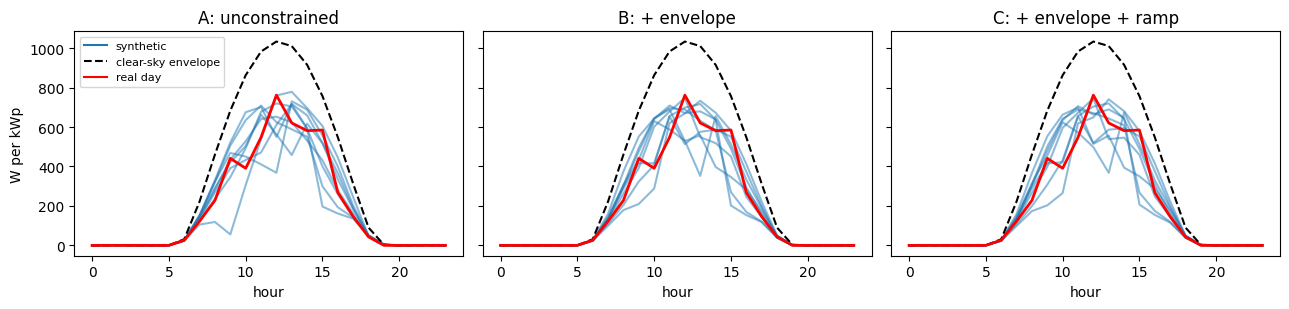

,night,negative,above_env,ramp
A: unconstrained,0.885,1.0,0.892,0.0
B: + envelope,0.000,0.0,0.000,0.0
C: + envelope + ramp,0.000,0.0,0.000,0.0


In [ ]:
from matplotlib.lines import Line2D
i = int(np.argmin(np.abs(TE["kt"] - 0.6)))                       # a partly cloudy test day
one = {k: v[i:i+1] for k, v in TE.items()}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a, v in zip(ax, VARIANTS):
    P_s, E_s = sample(models[(v,0)], one, n_per=8, seed=1)
    for row in P_s: a.plot(row, color="tab:blue", alpha=.5)
    a.plot(E_s[0], "k--", lw=1.5); a.plot(TE["P"][i], "r", lw=2); a.set_title(v); a.set_xlabel("hour")
ax[0].set_ylabel("W per kWp")
ax[0].legend([Line2D([0],[0],color="tab:blue"), Line2D([0],[0],color="k",ls="--"), Line2D([0],[0],color="r")],
             ["synthetic","clear-sky envelope","real day"], fontsize=8)
plt.tight_layout(); plt.show()

# Which physical rule does each variant break?
P_all = {v: sample(models[(v,0)], TE, seed=0) for v in VARIANTS}
pd.DataFrame({v: violation_parts(*P_all[v]) for v in VARIANTS}).T.round(3)

## 6. Save for Notebook 3

In [ ]:
R.to_csv("results_nb2.csv", index=False)
torch.save({f"{k[0]}|{k[1]}": m.state_dict() for k, m in models.items()}, "cvae_models.pt")
np.savez("synthetic_test_conditions.npz", **{v.split(":")[0]: P_all[v][0] for v in VARIANTS})
print("saved results_nb2.csv, cvae_models.pt, synthetic_test_conditions.npz")

saved results_nb2.csv, cvae_models.pt, synthetic_test_conditions.npz


### What to look for
- **A** should show violations (negative output, night power, above the envelope).
- **B** should drive night and envelope violations to about 0 by construction. A remaining ramp violation is expected.
- **C** should reduce ramp violations further, possibly at a small cost in fidelity.
- **Novelty** should be clearly above the bootstrap's 0 for all three. If it is also tiny, the models are memorizing.
- If a variant has worse fidelity than the bootstrap *and* more violations, the model is not earning its place yet. That is a legitimate finding, and Notebook 3 reports it honestly.